## Step 1: Python and NumPy

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
from sklearn.preprocessing import StandardScaler, LabelEncoder

dataset_path = 'netflix_titles.csv'
print(f"Loading dataset from: {dataset_path}")
df_raw = pd.read_csv(dataset_path)

release_years_arr = df_raw['release_year'].to_numpy()
movie_durations_arr = df_raw[df_raw['type'] == 'Movie']['duration'].dropna().str.replace(' min', '').astype(int).to_numpy()

custom_arr = np.arange(10, 110, 10)
print("Created NumPy Array:", custom_arr)
print("Indexing (element at index 2):", custom_arr[2])
print("Slicing (elements index 1 to 5):", custom_arr[1:6])
print("Arithmetic Operation (array * 2 + 5):", custom_arr * 2 + 5)

stats = {
    "Mean": np.mean(movie_durations_arr),
    "Median": np.median(movie_durations_arr),
    "Std Dev": np.std(movie_durations_arr),
    "Min": np.min(movie_durations_arr),
    "Max": np.max(movie_durations_arr),
    "25th Percentile": np.percentile(movie_durations_arr, 25),
    "75th Percentile": np.percentile(movie_durations_arr, 75)
}

print("\n--- NumPy Statistics for Movie Duration (Minutes) ---")
for stat, val in stats.items():
    print(f"{stat}: {val:,.2f}")

decades_arr = (release_years_arr // 10) * 10
print("\nSample Release Years (First 5):", release_years_arr[:5])
print("Sample Calculated Decades (First 5):", decades_arr[:5])

Loading dataset from: netflix_titles.csv
Created NumPy Array: [ 10  20  30  40  50  60  70  80  90 100]
Indexing (element at index 2): 30
Slicing (elements index 1 to 5): [20 30 40 50 60]
Arithmetic Operation (array * 2 + 5): [ 25  45  65  85 105 125 145 165 185 205]

--- NumPy Statistics for Movie Duration (Minutes) ---
Mean: 99.58
Median: 98.00
Std Dev: 28.29
Min: 3.00
Max: 312.00
25th Percentile: 87.00
75th Percentile: 114.00

Sample Release Years (First 5): [2020 2021 2021 2021 2021]
Sample Calculated Decades (First 5): [2020 2020 2020 2020 2020]


## Step 2: Pandas Operations

In [2]:
df = pd.read_csv(dataset_path)

print("--- First Five Records ---")
display(df.head())

print("--- Last Five Records ---")
display(df.tail())

print(f"\nNumber of Rows: {df.shape[0]}, Number of Columns: {df.shape[1]}")

print("\n--- Column Names and Data Types ---")
print(df.dtypes)

print("\n--- Summary Statistics ---")
display(df.describe(include='all'))

missing_values = df.isnull().sum()
missing_percentage = (df.isnull().sum() / len(df)) * 100
missing_df = pd.DataFrame({'Missing Values': missing_values, 'Percentage (%)': missing_percentage})
print("\n--- Missing Values Summary ---")
display(missing_df)

duplicate_count = df.duplicated().sum()
print(f"\nNumber of duplicate rows: {duplicate_count}")

--- First Five Records ---
--- Last Five Records ---

Number of Rows: 8807, Number of Columns: 12

--- Column Names and Data Types ---
show_id         object
type            object
title           object
director        object
cast            object
country         object
date_added      object
release_year     int64
rating          object
duration        object
listed_in       object
description     object
dtype: object

--- Summary Statistics ---

--- Missing Values Summary ---

Number of duplicate rows: 0


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
0,s1,Movie,Dick Johnson Is Dead,Kirsten Johnson,NaN,United States,"September 25, 2021",2020,PG-13,90 min,Documentaries,"As her father nears the end of his life, filmmaker Kirsten Johnson stages his death in inventive and comical ways to help them both face the inevitable."
1,s2,TV Show,Blood & Water,NaN,"Ama Qamata, Khosi Ngema, Gail Mabalane, Thabang Molaba, Dillon Windvogel, Natasha Thahane, Arno Greeff, Xolile Tshabalala, Getmore Sithole, Cindy Mahlangu, Ryle De Morny, Greteli Fincham, Sello Maake Ka-Ncube, Odwa Gwanya, Mekaila Mathys, Sandi Schultz, Duane Williams, Shamilla Miller, Patrick Mofokeng",South Africa,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, TV Dramas, TV Mysteries","After crossing paths at a party, a Cape Town teen sets out to prove whether a private-school swimming star is her sister who was abducted at birth."
2,s3,TV Show,Ganglands,Julien Leclercq,"Sami Bouajila, Tracy Gotoas, Samuel Jouy, Nabiha Akkari, Sofia Lesaffre, Salim Kechiouche, Noureddine Farihi, Geert Van Rampelberg, Bakary Diombera",NaN,"September 24, 2021",2021,TV-MA,1 Season,"Crime TV Shows, International TV Shows, TV Action & Adventure","To protect his family from a powerful drug lord, skilled thief Mehdi and his expert team of robbers are pulled into a violent and deadly turf war."
3,s4,TV Show,Jailbirds New Orleans,NaN,NaN,NaN,"September 24, 2021",2021,TV-MA,1 Season,"Docuseries, Reality TV","Feuds, flirtations and toilet talk go down among the incarcerated women at the Orleans Justice Center in New Orleans on this gritty reality series."
4,s5,TV Show,Kota Factory,NaN,"Mayur More, Jitendra Kumar, Ranjan Raj, Alam Khan, Ahsaas Channa, Revathi Pillai, Urvi Singh, Arun Kumar",India,"September 24, 2021",2021,TV-MA,2 Seasons,"International TV Shows, Romantic TV Shows, TV Comedies","In a city of coaching centers known to train India’s finest collegiate minds, an earnest but unexceptional student and his friends navigate campus life."


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
8802,s8803,Movie,Zodiac,David Fincher,"Mark Ruffalo, Jake Gyllenhaal, Robert Downey Jr., Anthony Edwards, Brian Cox, Elias Koteas, Donal Logue, John Carroll Lynch, Dermot Mulroney, Chloë Sevigny",United States,"November 20, 2019",2007,R,158 min,"Cult Movies, Dramas, Thrillers","A political cartoonist, a crime reporter and a pair of cops investigate San Francisco's infamous Zodiac Killer in this thriller based on a true story."
8803,s8804,TV Show,Zombie Dumb,NaN,NaN,NaN,"July 1, 2019",2018,TV-Y7,2 Seasons,"Kids' TV, Korean TV Shows, TV Comedies","While living alone in a spooky town, a young girl befriends a motley crew of zombie children with diverse personalities."
8804,s8805,Movie,Zombieland,Ruben Fleischer,"Jesse Eisenberg, Woody Harrelson, Emma Stone, Abigail Breslin, Amber Heard, Bill Murray, Derek Graf",United States,"November 1, 2019",2009,R,88 min,"Comedies, Horror Movies","Looking to survive in a world taken over by zombies, a dorky college student teams with an urban roughneck and a pair of grifter sisters."
8805,s8806,Movie,Zoom,Peter Hewitt,"Tim Allen, Courteney Cox, Chevy Chase, Kate Mara, Ryan Newman, Michael Cassidy, Spencer Breslin, Rip Torn, Kevin Zegers",United States,"January 11, 2020",2006,PG,88 min,"Children & Family Movies, Comedies","Dragged from civilian life, a former superhero must train a new crop of youthful saviors when the military preps for an attack by a familiar villain."
8806,s8807,Movie,Zubaan,Mozez Singh,"Vicky Kaushal, Sarah-Jane Dias, Raaghav Chanana, Manish Chaudhary, Meghna Malik, Malkeet Rauni, Anita Shabdish, Chittaranjan Tripathy",India,"March 2, 2019",2015,TV-14,111 min,"Dramas, International Movies, Music & Musicals","A scrappy but poor boy worms his way into a tycoon's dysfunctional family, while facing his fear of music and the truth about his past."


,show_id,type,title,director,cast,country,date_added,release_year,rating,duration,listed_in,description
count,8807,8807,8807,6173,7982,7976,8797,8807.000000,8803,8804,8807,8807
unique,8807,2,8807,4528,7692,748,1767,NaN,17,220,514,8775
top,s1,Movie,Dick Johnson Is Dead,Rajiv Chilaka,David Attenborough,United States,"January 1, 2020",NaN,TV-MA,1 Season,"Dramas, International Movies","Paranormal activity at a lush, abandoned property alarms a group eager to redevelop the site, but the eerie events may not be as unearthly as they think."
freq,1,6131,1,19,19,2818,109,NaN,3207,1793,362,4
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2014.180198,NaN,NaN,NaN,NaN
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,8.819312,NaN,NaN,NaN,NaN
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1925.000000,NaN,NaN,NaN,NaN
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2013.000000,NaN,NaN,NaN,NaN
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2017.000000,NaN,NaN,NaN,NaN
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,2019.000000,NaN,NaN,NaN,NaN


,Missing Values,Percentage (%)
show_id,0,0.000000
type,0,0.000000
title,0,0.000000
director,2634,29.908028
cast,825,9.367549
country,831,9.435676
date_added,10,0.113546
release_year,0,0.000000
rating,4,0.045418
duration,3,0.034064


## Step 3: Data Cleaning and Preprocessing

In [3]:
shape_before = df.shape
missing_before = df.isnull().sum().sum()
dtypes_before = df.dtypes.copy()

df.columns = df.columns.str.strip().str.lower().str.replace(' ', '_')

df.drop_duplicates(inplace=True)

df['director'] = df['director'].fillna('Unknown')
df['cast'] = df['cast'].fillna('Unknown')
df['country'] = df['country'].fillna(df['country'].mode()[0])
df['date_added'] = df['date_added'].fillna(df['date_added'].mode()[0])
df['rating'] = df['rating'].fillna(df['rating'].mode()[0])
df['duration'] = df['duration'].fillna('0 min')

df['date_added_clean'] = pd.to_datetime(df['date_added'].str.strip(), errors='coerce')
df['date_added_clean'] = df['date_added_clean'].fillna(df['date_added_clean'].mode()[0])

df['duration_num'] = df['duration'].str.extract(r'(\d+)').astype(float)
df['duration_unit'] = df['duration'].str.extract(r'([a-zA-Z]+)').fillna('min')

Q1 = df['release_year'].quantile(0.25)
Q3 = df['release_year'].quantile(0.75)
IQR = Q3 - Q1
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR
outliers_release = df[(df['release_year'] < lower_bound) | (df['release_year'] > upper_bound)]
print(f"Release Year Outliers Detected (IQR method): {len(outliers_release)} records (Lower Bound: {lower_bound}, Upper Bound: {upper_bound})")

comparison_df = pd.DataFrame({
    'Metric': ['Row Count', 'Column Count', 'Total Missing Values', 'Duplicate Rows'],
    'Before Cleaning': [shape_before[0], shape_before[1], missing_before, duplicate_count],
    'After Cleaning': [df.shape[0], df.shape[1], df.isnull().sum().sum(), df.duplicated().sum()]
})
print("\n--- Dataset Comparison Before and After Cleaning ---")
display(comparison_df)

Release Year Outliers Detected (IQR method): 719 records (Lower Bound: 2004.0, Upper Bound: 2028.0)

--- Dataset Comparison Before and After Cleaning ---


,Metric,Before Cleaning,After Cleaning
0,Row Count,8807,8807
1,Column Count,12,15
2,Total Missing Values,4307,0
3,Duplicate Rows,0,0


## Step 4: Exploratory Data Analysis (EDA)

In [4]:
print("--- Descriptive Statistical Analysis (Numerical) ---")
display(df[['release_year', 'duration_num']].describe())

print("\n--- Categorical Variable Analysis: Content Type ---")
display(df['type'].value_counts())

print("\n--- Categorical Variable Analysis: Top 10 Ratings ---")
display(df['rating'].value_counts().head(10))

print("\n--- Categorical Variable Analysis: Top 10 Countries ---")
display(df['country'].value_counts().head(10))

df['year_added'] = df['date_added_clean'].dt.year
df['month_added'] = df['date_added_clean'].dt.month
df['release_to_add_lag'] = df['year_added'] - df['release_year']

print("\n--- Correlation Matrix (Numerical Variables) ---")
correlation_matrix = df[['release_year', 'duration_num', 'year_added', 'month_added', 'release_to_add_lag']].corr()
display(correlation_matrix)

--- Descriptive Statistical Analysis (Numerical) ---

--- Categorical Variable Analysis: Content Type ---

--- Categorical Variable Analysis: Top 10 Ratings ---

--- Categorical Variable Analysis: Top 10 Countries ---

--- Correlation Matrix (Numerical Variables) ---


,release_year,duration_num
count,8807.000000,8807.000000
mean,2014.180198,69.823095
std,8.819312,50.822520
min,1925.000000,0.000000
25%,2013.000000,2.000000
50%,2017.000000,88.000000
75%,2019.000000,106.000000
max,2021.000000,312.000000


type
Movie      6131
TV Show    2676
Name: count, dtype: int64

rating
TV-MA    3211
TV-14    2160
TV-PG     863
R         799
PG-13     490
TV-Y7     334
TV-Y      307
PG        287
TV-G      220
NR         80
Name: count, dtype: int64

country
United States     3649
India              972
United Kingdom     419
Japan              245
South Korea        199
Canada             181
Spain              145
France             124
Mexico             110
Egypt              106
Name: count, dtype: int64

,release_year,duration_num,year_added,month_added,release_to_add_lag
release_year,1.000000,-0.249087,0.111206,-0.038500,-0.984023
duration_num,-0.249087,1.000000,0.029010,-0.014942,0.255267
year_added,0.111206,0.029010,1.000000,-0.161465,0.067510
month_added,-0.038500,-0.014942,-0.161465,1.000000,0.009725
release_to_add_lag,-0.984023,0.255267,0.067510,0.009725,1.000000


### Key Observations from Exploratory Data Analysis
1. **Catalog Composition:** Movies account for roughly 69.6% (6,131 titles) of the Netflix catalog, while TV Shows make up approximately 30.4% (2,676 titles).
2. **Geographic Concentration:** The United States is the dominant content producer on Netflix, followed by India and the United Kingdom.
3. **Target Audience Ratings:** Mature ratings such as `TV-MA` and `TV-14` represent the largest segments of the catalog, indicating a strong focus on adult and teen audiences.
4. **Content Growth Over Time:** Content additions accelerated sharply after 2015, peaking around 2019–2020, with most titles released after 2010.
5. **Release-to-Addition Correlation:** `release_year` and `release_to_add_lag` show a strong negative correlation because older classic titles have a much longer gap before being added to Netflix compared to recent Netflix Originals.

## Step 5: Data Visualization Using Matplotlib

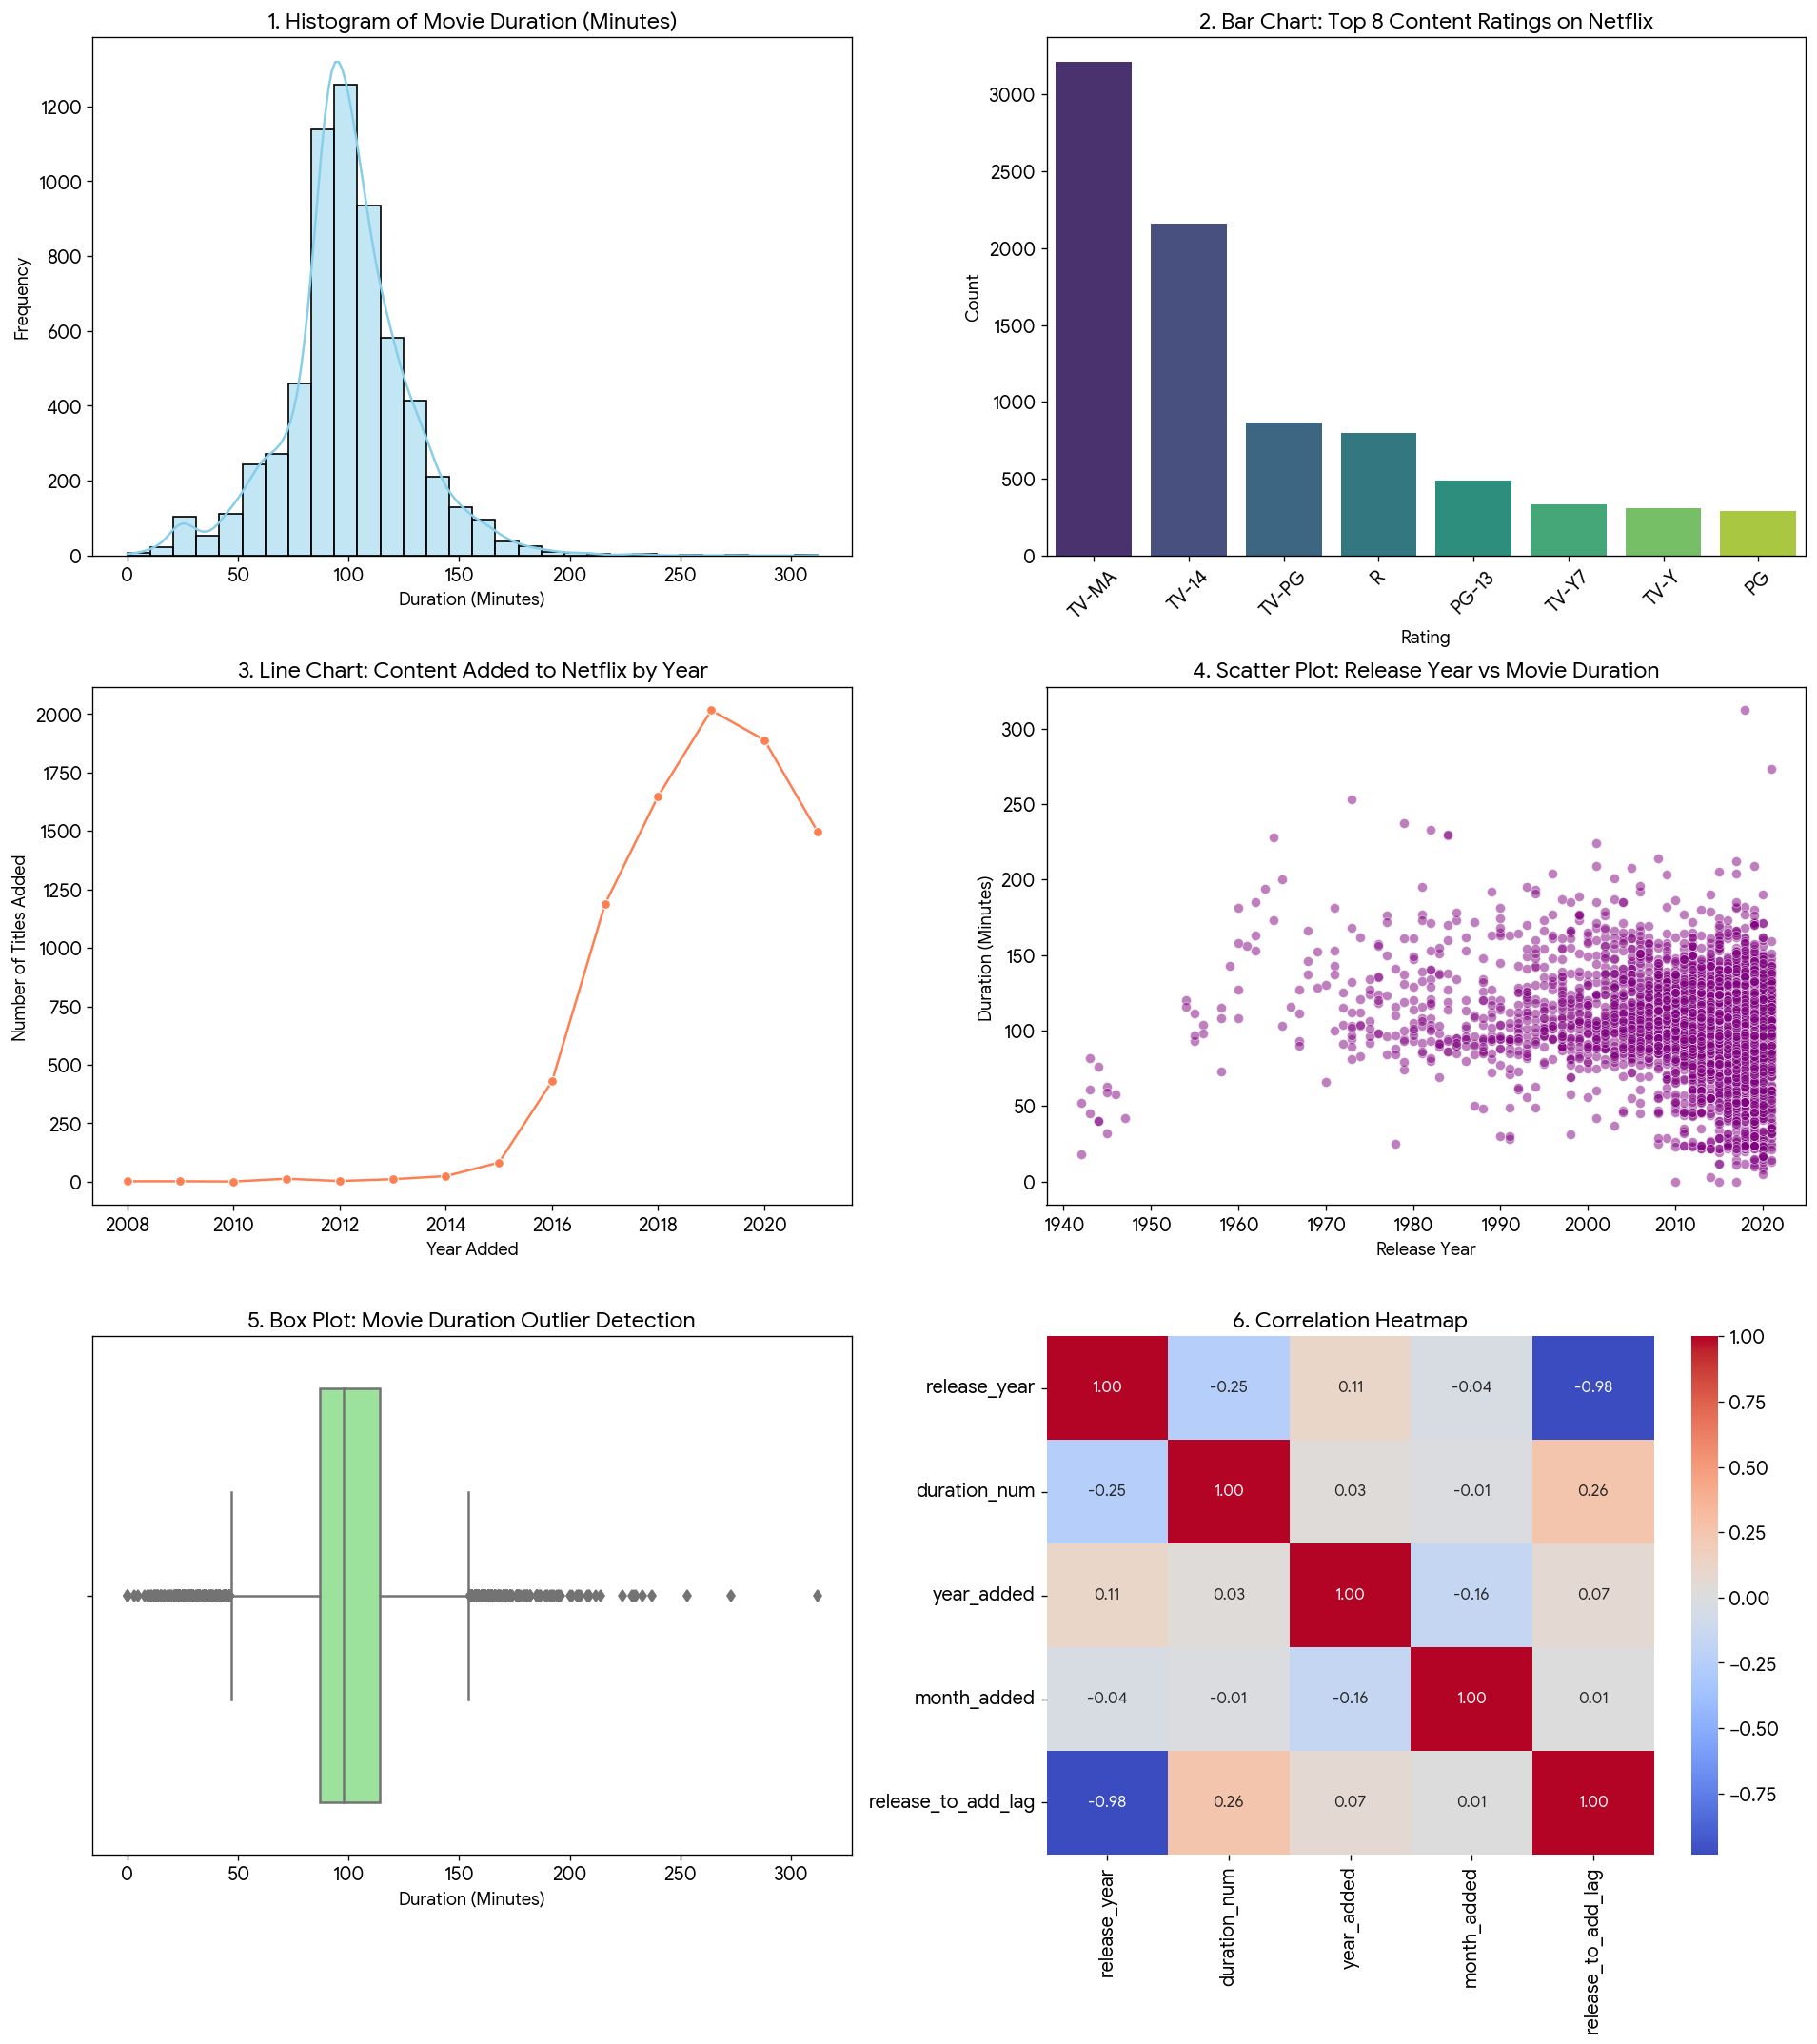

In [5]:
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

movies_df = df[df['type'] == 'Movie']
sns.histplot(movies_df['duration_num'], bins=30, kde=True, ax=axes[0, 0], color='skyblue')
axes[0, 0].set_title('1. Histogram of Movie Duration (Minutes)')
axes[0, 0].set_xlabel('Duration (Minutes)')
axes[0, 0].set_ylabel('Frequency')

top_ratings = df['rating'].value_counts().head(8).reset_index()
top_ratings.columns = ['rating', 'count']
sns.barplot(data=top_ratings, x='rating', y='count', ax=axes[0, 1], palette='viridis')
axes[0, 1].set_title('2. Bar Chart: Top 8 Content Ratings on Netflix')
axes[0, 1].set_xlabel('Rating')
axes[0, 1].set_ylabel('Count')
axes[0, 1].tick_params(axis='x', rotation=45)

yearly_additions = df.groupby('year_added')['show_id'].count().reset_index()
sns.lineplot(data=yearly_additions, x='year_added', y='show_id', ax=axes[1, 0], color='coral', marker='o')
axes[1, 0].set_title('3. Line Chart: Content Added to Netflix by Year')
axes[1, 0].set_xlabel('Year Added')
axes[1, 0].set_ylabel('Number of Titles Added')

sns.scatterplot(data=movies_df, x='release_year', y='duration_num', alpha=0.5, ax=axes[1, 1], color='purple')
axes[1, 1].set_title('4. Scatter Plot: Release Year vs Movie Duration')
axes[1, 1].set_xlabel('Release Year')
axes[1, 1].set_ylabel('Duration (Minutes)')

sns.boxplot(x=movies_df['duration_num'], ax=axes[2, 0], color='lightgreen')
axes[2, 0].set_title('5. Box Plot: Movie Duration Outlier Detection')
axes[2, 0].set_xlabel('Duration (Minutes)')

corr_cols = ['release_year', 'duration_num', 'year_added', 'month_added', 'release_to_add_lag']
sns.heatmap(df[corr_cols].corr(numeric_only=True), annot=True, cmap='coolwarm', fmt='.2f', ax=axes[2, 1])
axes[2, 1].set_title('6. Correlation Heatmap')

plt.tight_layout()
plt.show()

## Step 6: Interactive Visualization Using Plotly

In [6]:
fig_hist = px.histogram(
    df[df['release_year'] >= 1980],
    x='release_year',
    color='type',
    nbins=40,
    barmode='overlay',
    title='Interactive Histogram: Content Distribution by Release Year (1980-2021)',
    labels={'release_year': 'Release Year', 'type': 'Content Type', 'count': 'Number of Titles'},
    color_discrete_sequence=['#E50914', '#221F1F']
)
fig_hist.update_layout(xaxis_title='Release Year', yaxis_title='Count of Titles', legend_title='Content Type')
fig_hist.show()

fig_scatter = px.scatter(
    movies_df[movies_df['release_year'] >= 1980],
    x='release_year',
    y='duration_num',
    color='rating',
    hover_data=['title', 'country', 'year_added'],
    title='Interactive Scatter Plot: Movie Release Year vs Duration by Rating',
    labels={'release_year': 'Release Year', 'duration_num': 'Duration (Minutes)', 'rating': 'Rating'}
)
fig_scatter.update_layout(xaxis_title='Release Year', yaxis_title='Duration (Minutes)', legend_title='Rating')
fig_scatter.show()

top_countries_type = df[df['country'].isin(df['country'].value_counts().head(10).index)]
country_counts = top_countries_type.groupby(['country', 'type']).size().reset_index(name='count')
fig_bar = px.bar(
    country_counts,
    x='country',
    y='count',
    color='type',
    barmode='group',
    title='Interactive Bar Chart: Top 10 Content Producing Countries by Type',
    labels={'country': 'Country', 'count': 'Number of Titles', 'type': 'Content Type'},
    hover_data=['country', 'type', 'count']
)
fig_bar.update_layout(xaxis_title='Country', yaxis_title='Number of Titles', legend_title='Content Type')
fig_bar.show()

Figure({
    'data': [{'alignmentgroup': 'True',
              'bingroup': 'x',
              'hovertemplate': 'Content Type=Movie<br>Release Year=%{x}<br>count=%{y}<extra></extra>',
              'legendgroup': 'Movie',
              'marker': {'color': '#E50914', 'opacity': 0.5, 'pattern': {'shape': ''}},
              'name': 'Movie',
              'nbinsx': 40,
              'offsetgroup': 'Movie',
              'orientation': 'v',
              'showlegend': True,
              'type': 'histogram',
              'x': array([2020, 2021, 1993, ..., 2009, 2006, 2015]),
              'xaxis': 'x',
              'yaxis': 'y'},
             {'alignmentgroup': 'True',
              'bingroup': 'x',
              'hovertemplate': 'Content Type=TV Show<br>Release Year=%{x}<br>count=%{y}<extra></extra>',
              'legendgroup': 'TV Show',
              'marker': {'color': '#221F1F', 'opacity': 0.5, 'pattern': {'shape': ''}},
              'name': 'TV Show',
              'nbinsx': 40,


Figure({
    'data': [{'customdata': array([['Dick Johnson Is Dead', 'United States', 2021],
                                   ['The Starling', 'United States', 2021],
                                   ['Grown Ups', 'United States', 2021],
                                   ...,
                                   ['XXx', 'United States', 2019],
                                   ['XXX: State of the Union', 'United States', 2019],
                                   ['Yoga Hosers', 'United States', 2016]], dtype=object),
              'hovertemplate': ('Rating=PG-13<br>Release Year=%' ... '{customdata[2]}<extra></extra>'),
              'legendgroup': 'PG-13',
              'marker': {'color': '#636efa', 'symbol': 'circle'},
              'mode': 'markers',
              'name': 'PG-13',
              'showlegend': True,
              'type': 'scattergl',
              'x': array([2020, 2021, 2010, ..., 2002, 2005, 2016]),
              'xaxis': 'x',
              'y': array([ 90., 104

Figure({
    'data': [{'alignmentgroup': 'True',
              'customdata': array([['Movie'],
                                   ['Movie'],
                                   ['Movie'],
                                   ['Movie'],
                                   ['Movie'],
                                   ['Movie'],
                                   ['Movie'],
                                   ['Movie'],
                                   ['Movie'],
                                   ['Movie']], dtype=object),
              'hovertemplate': ('Content Type=%{customdata[0]}<' ... ' of Titles=%{y}<extra></extra>'),
              'legendgroup': 'Movie',
              'marker': {'color': '#636efa', 'pattern': {'shape': ''}},
              'name': 'Movie',
              'offsetgroup': 'Movie',
              'orientation': 'v',
              'showlegend': True,
              'textposition': 'auto',
              'type': 'bar',
              'x': array(['Canada', 'Egypt', 'France', 'I

## Step 7: Feature Engineering

In [7]:
df['added_year'] = df['date_added_clean'].dt.year
df['added_month'] = df['date_added_clean'].dt.month
df['added_day_of_week'] = df['date_added_clean'].dt.day_name()

df['content_age_at_addition'] = (df['added_year'] - df['release_year']).clip(lower=0)
df['genre_count'] = df['listed_in'].apply(lambda x: len(str(x).split(',')))
df['cast_count'] = df['cast'].apply(lambda x: 0 if x == 'Unknown' else len(str(x).split(',')))
df['description_word_count'] = df['description'].apply(lambda x: len(str(x).split()))

le_type = LabelEncoder()
df['type_encoded'] = le_type.fit_transform(df['type'])

le_rating = LabelEncoder()
df['rating_encoded'] = le_rating.fit_transform(df['rating'])

top_5_countries = df['country'].value_counts().head(5).index
for c in top_5_countries:
    col_name = 'country_' + c.lower().replace(' ', '_')
    df[col_name] = df['country'].apply(lambda x: 1 if c in str(x) else 0)

scaler = StandardScaler()
num_cols_to_scale = ['release_year', 'duration_num', 'content_age_at_addition', 'genre_count', 'cast_count', 'description_word_count']
scaled_cols = [col + '_scaled' for col in num_cols_to_scale]
df[scaled_cols] = scaler.fit_transform(df[num_cols_to_scale])

print("--- Dataset with Engineered, Encoded, and Scaled Features ---")
display(df[['title', 'type', 'type_encoded', 'added_year', 'added_month', 'content_age_at_addition', 'genre_count', 'cast_count'] + scaled_cols].head())

--- Dataset with Engineered, Encoded, and Scaled Features ---


,title,type,type_encoded,added_year,added_month,content_age_at_addition,genre_count,cast_count,release_year_scaled,duration_num_scaled,content_age_at_addition_scaled,genre_count_scaled,cast_count_scaled,description_word_count_scaled
0,Dick Johnson Is Dead,Movie,0,2021,9,1,1,0,0.659930,0.397030,-0.420690,-1.522448,-1.497594,1.099136
1,Blood & Water,TV Show,1,2021,9,0,3,19,0.773324,-1.334584,-0.534547,1.027609,2.410289,1.099136
2,Ganglands,TV Show,1,2021,9,0,3,9,0.773324,-1.354262,-0.534547,1.027609,0.353508,1.099136
3,Jailbirds New Orleans,TV Show,1,2021,9,0,2,0,0.773324,-1.354262,-0.534547,-0.247419,-1.497594,0.041511
4,Kota Factory,TV Show,1,2021,9,0,3,8,0.773324,-1.334584,-0.534547,1.027609,0.147830,0.041511


## Step 8: Analysis and Conclusion
### 1. Summary of Major Findings

* The dataset contains **8,807 titles** across **12 columns** (~70% Movies and ~30% TV Shows).
* Missing values were mainly in `director` (~30%), `cast` (~9.4%), and `country` (~9.4%), which were imputed without dropping any rows.
* Movie duration averages **99.58 minutes** (median **98 minutes**), with some outliers over 200 minutes.

### 2. Important Patterns and Relationships

* **Recent Content Shift:** After 2016, Netflix added more newly released titles instead of only older ones.
* **Country Trends:** The US and India produce mostly Movies, while South Korea and Japan have more TV Shows.
* **Ratings:** `TV-MA` and `TV-14` are the top ratings, showing a focus on teen and adult audiences.

### 3. Conclusions and Recommendations

1. **Invest in TV Shows:** Keep adding local TV Shows in fast-growing markets like South Korea and Japan.
2. **Keep Standard Movie Lengths:** Target 87 to 114 minutes for new movies, as most titles fall in this range.
3. **Require Complete Metadata:** Ensure `director` and `cast` fields are filled when adding titles to improve search and recommendations.

### 4. Limitations

* **No Viewership Data:** Lacks watch hours, user ratings, or popularity scores.
* **Outdated Data:** Only covers titles up to late 2021.
* **Multi-Value Columns:** `country`, `cast`, and `listed_in` contain comma-separated lists, making exact grouping harder.